# HW3: Logistic Regression and Optimization

Welcome to the coding part of Homework 3. In this notebook, you will implement classification models from scratch using numpy. You will analyze the behavior of Gradient Descent, explore the effects of hyperparameters, and implement multiclass classification strategies (One-vs-Rest, One-vs-One, and Softmax).

# Due Date: Sunday, May 24, at 11:59 PM

This assignment is due on **Sunday, May 24, at 11:59 PM**. You must submit your work to LearnHub by this deadline.

**Dataset**: You will use the Wine Quality dataset (https://archive.ics.uci.edu/dataset/186/wine+quality) which contains physicochemical measurements of wines and a quality score assigned by human experts.

**Instructions**:

1. Do not use PyTorch, TensorFlow, or Scikit-Learn's LogisticRegression. You must implement the algorithms using numpy.
2. You may use sklearn only for data loading, splitting, and basic preprocessing (like scaling), but the core learning algorithms must be your own.
3. Fill in the code blocks marked with TODO.
4. Test your code thoroughly to ensure it meets the requirements.
5. Answer the conceptual questions with clear and concise written responses.

Good luck!

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Set random seed for reproducibility
np.random.seed(42)

%matplotlib inline

# 1. Load and visualize the data

In [25]:
# Load Data
import ssl
import urllib.request

context = ssl.create_default_context()
context.check_hostname = False
context.verify_mode = ssl.CERT_NONE

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

with urllib.request.urlopen(url, context=context) as response:
    data = pd.read_csv(response, sep=";")

X = data.drop("quality", axis=1).values
y_raw = data["quality"].values

print(f"Data shape: {X.shape}, Target shape: {y_raw.shape}")

Data shape: (4898, 11), Target shape: (4898,)


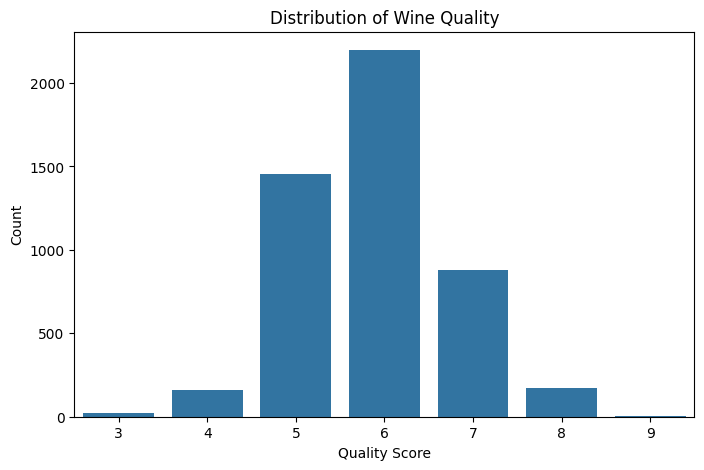

In [26]:
# Visualize the distribution of the target variable (quality)
plt.figure(figsize=(8, 5))
sns.countplot(x='quality', data=data)
plt.title('Distribution of Wine Quality')
plt.xlabel('Quality Score')
plt.ylabel('Count')
plt.show()

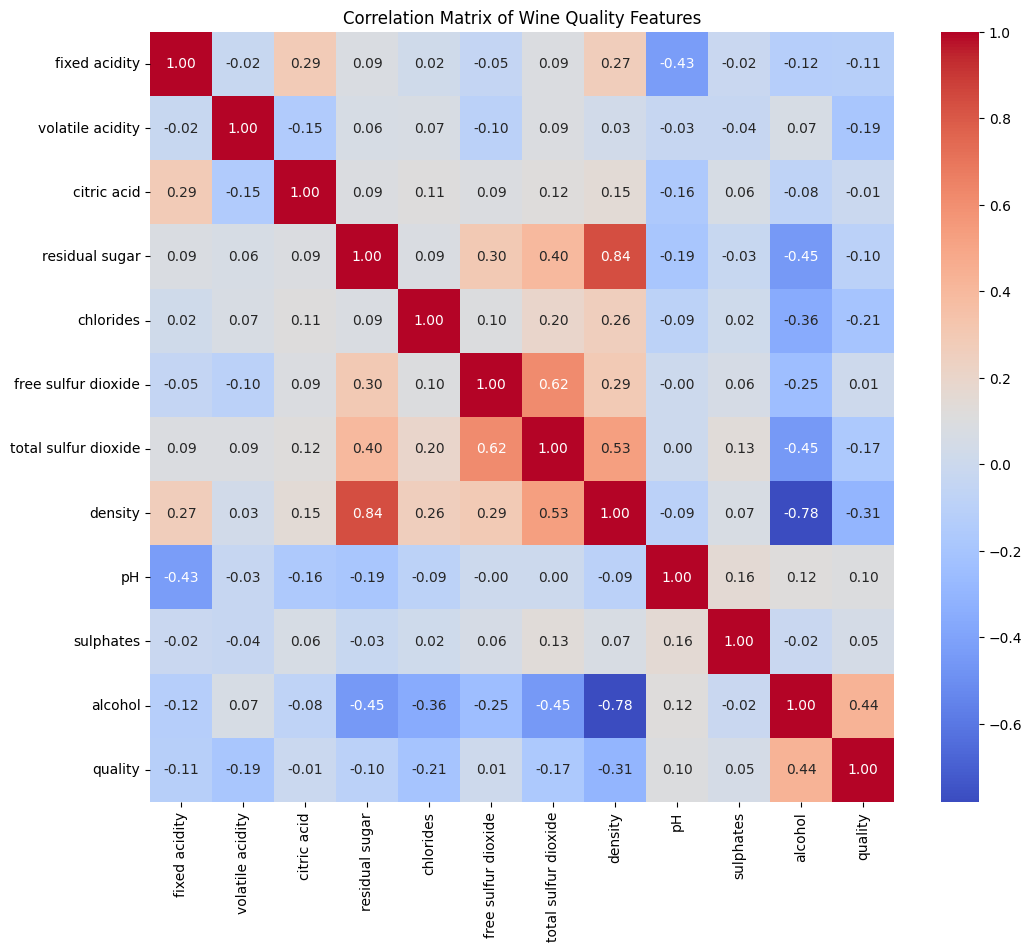

In [27]:
# Visualize the correlations between the features and the target variable
plt.figure(figsize=(12, 10))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Wine Quality Features')
plt.show()

**Q1**: Based on the visualizations, what observations can you make about the distribution of wine quality (the target variable) and the relationships between features? Are there any clear correlations visible?

**Answer**:
The target variable quality follows a nearly normal distribution that is heavily concentrated around average scores of 5 and 6, indicating an imbalanced dataset with very few instances of extremely high or low-quality wines. Looking at the correlation matrix, the strongest positive relationship exists between density and residual sugar (0.84), while density and alcohol exhibit the strongest negative correlation (-0.78). Regarding the target variable, alcohol has the most prominent positive correlation with quality (0.44), suggesting that higher alcohol content is generally associated with better quality ratings, whereas density shows a notable negative correlation (-0.31) with the final quality score.

# 2. Binary Logistic Regression

 We will start by simplifying the problem to a Binary Classification task. We will train a model to distinguish High Quality (Quality > 6) from Low Quality (Quality <= 6).

First, we will set the labels of the datapoints to 1 if the original label is higher than 6, to 0 otherwise. Additionally, we will map the original labels to class indices starting from 0 for multiclass classification that you will implement in the next steps.



In [28]:
# Binary labels: 1 if quality > 6, else 0
y_binary = (y_raw > 6).astype(int)

# Map original labels to class indices starting from 0. (for multiclass classification, do not worry about it right now)
quality_to_class = {}
qualities = np.unique(y_raw)
classes = np.arange(len(qualities))
for q, c in zip(qualities, classes):
    quality_to_class[q] = c

y_multi = np.array([quality_to_class[q] for q in y_raw])

print("Class distribution (original):", np.bincount(y_multi))
print("Class distribution (binary):", np.bincount(y_binary))

Class distribution (original): [  20  163 1457 2198  880  175    5]
Class distribution (binary): [3838 1060]


Next, we split the data into train, validation and test sets. We also apply standardization.

In [29]:
# Split data (80% train, 10% validation, 10% test)
np.random.seed(42)

n_samples = X.shape[0]

indices = np.arange(n_samples)
np.random.shuffle(indices)

train_ratio = 0.8
val_ratio = 0.1
test_ratio = 0.1

train_size = int(train_ratio * n_samples)
val_size = int(val_ratio * n_samples)
test_size = n_samples - train_size - val_size

train_indices = indices[:train_size]
val_indices = indices[train_size : train_size + val_size]
test_indices = indices[train_size + val_size :]

X_train, y_train, y_train_bin = X[train_indices], y_multi[train_indices], y_binary[train_indices]
X_val, y_val, y_val_bin = X[val_indices], y_multi[val_indices], y_binary[val_indices]
X_test, y_test, y_test_bin = X[test_indices], y_multi[test_indices], y_binary[test_indices]


# Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test) # Scale test set

We add the column of 1s to each split accounting for the bias term in the model.

In [30]:
# Add intercept term (bias)
# We append a column of ones to X so we can use dot product w^T x
def add_intercept(X):
    intercept = np.ones((X.shape[0], 1))
    return np.concatenate((intercept, X), axis=1)

X_train_aug = add_intercept(X_train_scaled)
X_val_aug = add_intercept(X_val_scaled)
X_test_aug = add_intercept(X_test_scaled) # Add intercept to test set

print("Shape after adding intercept (Train):", X_train_aug.shape)
print("Shape after adding intercept (Validation):", X_val_aug.shape)
print("Shape after adding intercept (Test):", X_test_aug.shape)

Shape after adding intercept (Train): (3918, 12)
Shape after adding intercept (Validation): (489, 12)
Shape after adding intercept (Test): (491, 12)


Now, you need to complete the implementation of LogisticRegressionBinary class with various functions:

*   **\_\_init\_\_** : Initializes the model instance by mainly storing the necessary hyperparameters such as the learning rate.

* **sigmoid**: Transforms raw linear predictions (logits) into probabilities by applying the sigmoid activation function.

* **compute_loss**: Calculates the binary cross-entropy cost to quantify the error between the model's predicted probabilities and the true target labels.

* **fit**: Trains the model by iteratively performing forward passes, calculating gradients, and updating weights via gradient descent to minimize loss.

* **get_probs**: Estimates the probability that a given input sample belongs to the positive class.

* **predict**: Converts predicted probabilities into binary class labels.


In [31]:
class LogisticRegressionBinary:
    def __init__(self, learning_rate=0.01, epochs=100, threshold=0.5):
        self.lr = learning_rate
        self.epochs = epochs
        self.threshold = threshold
        self.weights = None
        self.train_loss_history = []
        self.val_loss_history = []

    def sigmoid(self, logits):
        # Clip logits to avoid overflow/underflow
        logits = np.clip(logits, -250, 250)

        # TODO: Implement sigmoid function
        return 1 / (1 + np.exp(-logits))

    def get_probs(self, X):
        # TODO: Implement this function that will perform the forward pass (linear model + sigmoid) and return the probabilities assigned.

        logits = np.dot(X, self.weights)
        return self.sigmoid(logits)

    def compute_loss(self, y_true, y_pred):
        # Add small constant to avoid log(0)
        y_pred = np.clip(y_pred, 1e-15, 1 - 1e-15)

        # TODO: Implement the binary cross-entropy loss
        loss = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
        return loss

    def fit(self, X_train, y_train, X_val=None, y_val=None):
        n, f = X_train.shape
        # Weight Initialization with random small weights
        self.weights = np.random.rand(f) * 0.01

        for i in range(self.epochs):
            # TODO: Forward pass (linear model + sigmoid)
            y_pred_train = self.get_probs(X_train)

            # TODO: Compute loss (call self.compute_loss that you implemented)
            loss_train = self.compute_loss(y_train, y_pred_train)
            self.train_loss_history.append(loss_train)

            # TODO: Backward pass (gradient descent)
            # Calculate the gradient and perform the parameter update
            gradient = np.dot(X_train.T, (y_pred_train - y_train)) / n
            self.weights -= self.lr * gradient
            # Validation
            if X_val is not None and y_val is not None:
              # TODO: Forward pass (linear model + sigmoid)
              y_pred_val = self.get_probs(X_val)

              # TODO: Compute loss (call self.compute_loss that you implemented)
              loss_val = self.compute_loss(y_val, y_pred_val)
              self.val_loss_history.append(loss_val)

              # No gradient descent here since this is the validation set.

    def predict(self, X):
        # TODO: Implement this function which will output the model prediction (1 or 0) on X
        probs = self.get_probs(X)
        return (probs >= self.threshold).astype(int)

**Q2:** In the context of this assignment, explain the following terms in 1-2 sentences each:
learning rate, epochs, threshold, weight initialization, convergence.

**Answer**:
In the context of this assignment, learning rate is a hyperparameter that controls the step size taken during gradient descent to update model parameters, while epochs define the total number of complete passes the training algorithm makes through the entire dataset. Threshold is the probability value used to map continuous model outputs to discrete binary class labels, weight initialization is the process of setting the initial random starting values of parameters to break symmetry before optimization, and convergence is the stable state reached when the model's loss plateaus and further training iterations no longer significantly improve performance.

Now, train the model for 50 epochs with different learning rates. Then, we will plot the training and validation loss as a function of epochs for each learning rate.

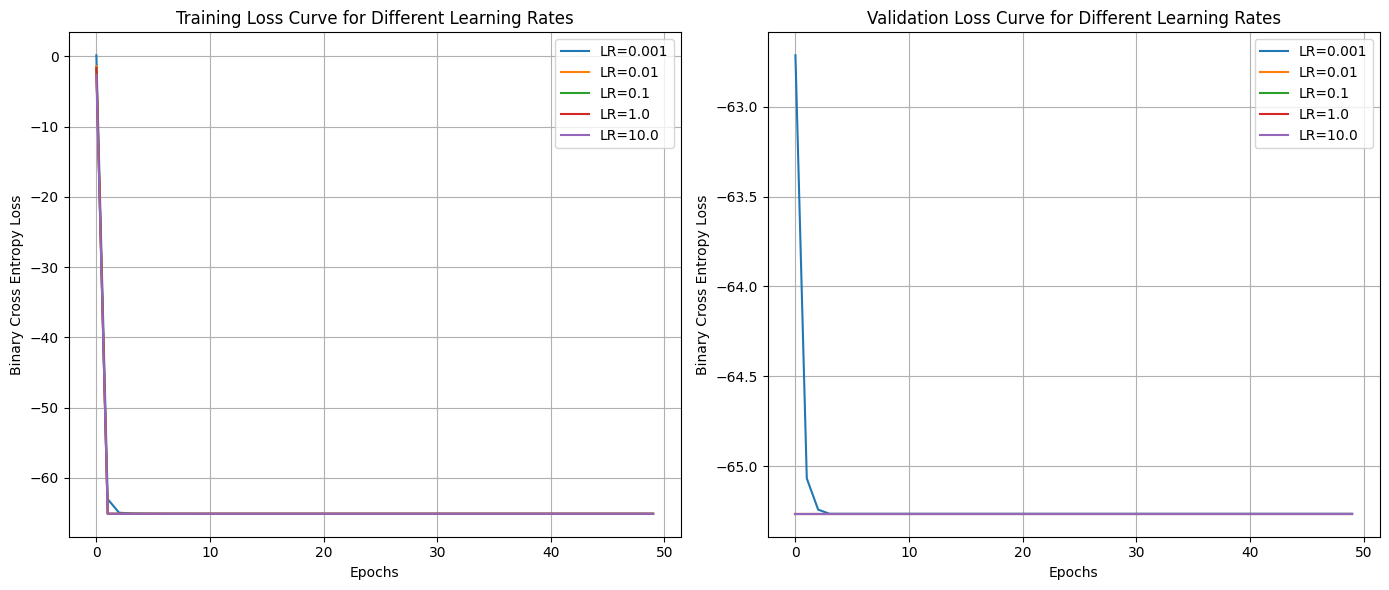

In [32]:
np.random.seed(42)

learning_rates = [0.001, 0.01, 0.1, 1.0, 10.0]
train_losses = {}
val_losses = {}
models_lr = {}

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)

for lr in learning_rates:
    # TODO: Initialize and train LogisticRegressionBinary model for 50 epochs.
    model = LogisticRegressionBinary(learning_rate=lr, epochs=50)
    model.fit(X_train, y_train, X_val, y_val)
    train_losses[lr] = model.train_loss_history
    val_losses[lr] = model.val_loss_history
    models_lr[lr] = model

    # Subplot for train losses
    plt.plot(model.train_loss_history, label=f'LR={lr}')

plt.title('Training Loss Curve for Different Learning Rates')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross Entropy Loss')
plt.legend()
plt.grid(True)

# Subplot for validation losses
plt.subplot(1, 2, 2)
for lr in learning_rates:
    plt.plot(val_losses[lr], label=f'LR={lr}')

plt.title('Validation Loss Curve for Different Learning Rates')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross Entropy Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Q3**: How does the choice of learning rate affect convergence behavior? Discuss the borderline cases of very small and very large learning rates.
  
**Answer**:
The choice of learning rate fundamentally dictates the model's convergence speed and stability during training. A well-tuned learning rate allows the model to smoothly and efficiently descend toward the minimum loss. In contrast, borderline cases present severe challenges: an extremely small learning rate (such as 0.001) takes excessively conservative steps, causing the model to train painfully slowly and risking getting stuck in local minima before reaching optimal convergence. Conversely, a very large learning rate (such as 10.0) can cause the parameter updates to completely overshoot the optimal minimum, leading to erratic behavior where the loss oscillates violently or entirely diverges, preventing the model from ever converging.

Now, predict labels using the model trained with learning_rate = 0.1  for the test split and (using scikit-learn) compute and print classification metrics: accuracy, precision, recall, F1.

In [33]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model = models_lr[0.1]

# TODO: First, get the model predictions on the test set, then evaluate the predictions using the imported functions.
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')

print(f"Test Accuracy:  {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1 Score:  {f1:.4f}")


Test Accuracy:  0.0407
Test Precision: 0.0058
Test Recall:    0.1429
Test F1 Score:  0.0112


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Q4**: You should observe that the accuracy is sufficiently high but the other metrics are not. What may be the reason behind this difference? Why/when can accuracy be misleading and how do the other metrics help?

**Answer:**
The core reason behind this discrepancy is that the dataset is highly imbalanced, combined with the fact that you trained a binary logistic regression model on a multiclass dataset. Because a binary classifier can only predict two outcomes, it completely misses the other wine quality classes present in the test set.
Accuracy is highly misleading here because if a dataset has a dominant majority class (or if a binary model's limited outputs happen to line up with a specific subset of the data), the accuracy score can look artificially high while the model completely fails to capture the true distribution of all target classes. Precision, Recall, and F1-score reveal this failure because they evaluate performance per class; since the binary model cannot even predict the other existing class labels, its True Positives for those categories are zero, driving the macro-averaged Precision and Recall down to nearly 0.0.

**Bonus**: As you observed, standard logistic regression may be biased toward the majority class with imbalanced datasets. One possible solution is to weight the loss and corresponding gradients so that errors on the minority class are penalized more heavily. Now, implement a class WeightedLogisticRegressionBinary that follows the same structure as LogisticRegressionBinary, but modifies the loss and gradient computations as follows:

* Assign a weight  $w_{\text{minor}} = \frac{\text{number of majority-class samples}}{\text{number of minority-class samples}}$ to samples belonging to the minority class.
* Assign a weight of 1 to samples belonging to the majority class.

Use these weights when computing both the binary cross-entropy loss and its gradients.

Then:
* Train the weighted model for 50 epochs using a learning rate of 0.1.

* Evaluate the trained model on the test set using accuracy, precision, recall, and F1-score.

* Compare the results with the unweighted logistic regression model.
You should observe an increase in F1-score, reflecting improved performance on the minority class.

In [34]:
class WeightedLogisticRegressionBinary:
    #TODO
    def __init__(self, learning_rate=0.01, epochs=100, threshold=0.5):
        self.lr = learning_rate
        self.epochs = epochs
        self.threshold = threshold
        self.weights = None
        self.train_loss_history = []
        self.val_loss_history = []
        self.w_minor = 1.0

    def sigmoid(self, logits):
        logits = np.clip(logits, -250, 250)
        return 1 / (1 + np.exp(-logits))

    def get_probs(self, X):
        logits = np.dot(X, self.weights)
        return self.sigmoid(logits)

    def compute_loss(self, y_true, y_pred, sample_weights):
        y_pred = np.clip(y_pred, 1e-15, 1 - 1e-15)
        raw_losses = -(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
        weighted_losses = sample_weights * raw_losses
        return np.mean(weighted_losses)

    def fit(self, X_train, y_train, X_val=None, y_val=None):
        n, f = X_train.shape
        self.weights = np.random.rand(f) * 0.01

        classes, counts = np.unique(y_train, return_counts=True)
        majority_idx = np.argmax(counts)
        minority_idx = np.argmin(counts)

        majority_class = classes[majority_idx]
        minority_class = classes[minority_idx]

        num_majority = counts[majority_idx]
        num_minority = counts[minority_idx]

        self.w_minor = num_majority / num_minority

        sample_weights_train = np.where(y_train == minority_class, self.w_minor, 1.0)

        if y_val is not None:
            sample_weights_val = np.where(y_val == minority_class, self.w_minor, 1.0)

        for i in range(self.epochs):
            y_pred_train = self.get_probs(X_train)

            loss_train = self.compute_loss(y_train, y_pred_train, sample_weights_train)
            self.train_loss_history.append(loss_train)

            weighted_errors = sample_weights_train * (y_pred_train - y_train)
            gradient = np.dot(X_train.T, weighted_errors) / n

            self.weights -= self.lr * gradient

            if X_val is not None and y_val is not None:
                y_pred_val = self.get_probs(X_val)
                loss_val = self.compute_loss(y_val, y_pred_val, sample_weights_val)
                self.val_loss_history.append(loss_val)

    def predict(self, X):
        probs = self.get_probs(X)
        return (probs >= self.threshold).astype(int)

# 3. Multiclass Classification

Now, we will return to the original settings and try to predict a class from more than 2 options for a given datapoint. In other words, we will perform multiclass classification.  

Remember that the dataset originally has 7 different labels (3, 4, 5, 6, 7, 8, 9) and we mapped these labels to class indices (0, 1, 2, 3, 4, 5, 6). In this part, you will implement three different approaches to train a multiclass classifier:


*   One-vs-Rest (OvR)
*   One-vs-One (OvO)
*   Softmax

**3.1 One-vs-Rest (OvR)**

In [35]:
np.random.seed(42)

class LogisticRegressionOvR:
    def __init__(self, learning_rate=0.1, epochs=50):
        self.lr = learning_rate
        self.epochs = epochs
        self.models = []
        self.classes = []

    def fit(self, X, y):
        # TODO: Extract unique classes from the data labels.
        # Then, train a binary classifier (use LogisticRegressionBinary that you implemented)
        # for each class and store each in self.models.
        self.classes = np.sort(np.unique(y))
        self.models = []

        for c in self.classes:
            y_binary = (y == c).astype(int)

            binary_model = LogisticRegressionBinary(learning_rate=self.lr, epochs=self.epochs)

            binary_model.fit(X, y_binary)

            self.models.append(binary_model)


    def predict(self, X):
        n_samples = X.shape[0]
        n_classes = len(self.classes)

        all_probs = np.zeros((n_samples, n_classes))

        for idx, model in enumerate(self.models):
            all_probs[:, idx] = model.get_probs(X)

        best_class_indices = np.argmax(all_probs, axis=1)

        return self.classes[best_class_indices]

# Train OvR and evaluate on the test split
ovr_model = LogisticRegressionOvR(learning_rate=0.1, epochs=50)
ovr_model.fit(X_train_aug, y_train)
y_pred_ovr = ovr_model.predict(X_test_aug)

print("OvR Accuracy:", accuracy_score(y_test, y_pred_ovr))

OvR Accuracy: 0.5437881873727087


**Q5**: Consider a multiclass classification problem with $K$ classes, trained using the One-vs-Rest (OvR) logistic regression approach on a dataset containing $N$ samples, each with $f$ features. Answer the following questions in terms of $N$, $f$ and $K$:

a) How many classifiers are trained?

Exactly K classifiers are trained. In the One-vs-Rest (OvR) approach, a separate binary logistic regression model is built for each unique class to determine whether an instance belongs to that specific class or any of the remaining ones.

b) What is the total number of parameters?

The total number of parameters is K×f. Each of the K binary classifiers learns its own weight vector of size f (where f is the number of features). Since the model implementation in this assignment does not explicitly use an independent bias term, each classifier has exactly f weights, scaling the total parameter count across all models to K×f.

c) How many training samples are used to train each classifier?

Each classifier is trained using all N samples available in the dataset. While the labels are temporarily mapped to binary values (1 for the target class and 0 for the rest), no data points are discarded during the training step of any individual sub-model.

**Answer:**

**3.2 One-vs-One (OvO)**

In [36]:
np.random.seed(42)

class LogisticRegressionOvO:
    def __init__(self, learning_rate=0.1, epochs=50):
        self.lr = learning_rate
        self.epochs = epochs
        self.models = []
        self.classes = []

    def fit(self, X, y):
        # TODO: Extract unique classes from the data labels.
        # Then, train a binary classifier (use LogisticRegressionBinary that you implemented)
        # for each pair of classes and store each in self.models.
        self.classes = np.sort(np.unique(y))
        self.models = []
        n_classes = len(self.classes)

        # TODO: Then, train a binary classifier (use LogisticRegressionBinary that you implemented)
        # for each pair of classes and store each in self.models.
        # Her benzersiz ikili kombinasyon (i ve j sınıfları) için bir döngü kuruyoruz
        for i in range(n_classes):
            for j in range(i + 1, n_classes):
                c1 = self.classes[i]
                c2 = self.classes[j]

                mask = (y == c1) | (y == c2)
                X_pair = X[mask]
                y_pair = y[mask]

                y_binary = (y_pair == c1).astype(int)

                binary_model = LogisticRegressionBinary(learning_rate=self.lr, epochs=self.epochs)
                binary_model.fit(X_pair, y_binary)

                self.models.append({
                    'model': binary_model,
                    'class1': c1,
                    'class2': c2
                })

    def predict(self, X):
        # TODO: Check predictions from each model and use majority voting for the final predictions.
        # Hint: Each binary classifier votes for one of the two labels it was trained on. Final prediction is the class with the highest vote.
        n_samples = X.shape[0]

        votes = np.zeros((n_samples, len(self.classes)))

        for model_info in self.models:
            binary_model = model_info['model']
            c1 = model_info['class1']
            c2 = model_info['class2']

            preds = binary_model.predict(X)

            c1_idx = np.where(self.classes == c1)[0][0]
            c2_idx = np.where(self.classes == c2)[0][0]

            votes[preds == 1, c1_idx] += 1
            votes[preds == 0, c2_idx] += 1

        best_class_indices = np.argmax(votes, axis=1)

        return self.classes[best_class_indices]

# Train OvO and evaluate on the test split
ovo_model = LogisticRegressionOvO(learning_rate=0.1, epochs=50)
ovo_model.fit(X_train_aug, y_train)
y_pred_ovo = ovo_model.predict(X_test_aug)

print("OvO Accuracy:", accuracy_score(y_test, y_pred_ovo))

OvO Accuracy: 0.5437881873727087


**Q6**: Consider a multiclass classification problem with $K$ classes, trained using the One-vs-One (OvO) logistic regression approach on a dataset containing $N$ samples, each with $f$ features. Answer the following questions in terms of $N$, $f$ and $K$:

a) How many classifiers are trained?

The total number of classifiers trained is K(K-1)/2.In the One-vs-One (OvO) approach, a unique binary classifier is trained for every possible pair of distinct classes to distinguish between them.

b) What is the total number of parameters?

The total number of parameters across all models is K(K-1)/2 x f Each trained binary classifier contains its own weight vector of size f. Since there are K(K-1)/2 classifiers and no separate bias term is used in this assignment's implementation, multiplying the number of classifiers by the number of features gives the total parameter count.

c) Assuming that the dataset contains an equal number of samples from each class, how many training samples are used to train each classifier?

Each classifier is trained using exactly 2N/K samples. If the total N samples are equally distributed among K classes, each individual class contains N/K samples. Because an OvO classifier isolates and trains strictly on the data points belonging to a specific pair of two classes, it utilizes N/K + N/K = 2N/K training samples, ignoring the rest of the dataset.

**Answer:**

**3.3 Softmax**

Softmax Accuracy: 0.5437881873727087


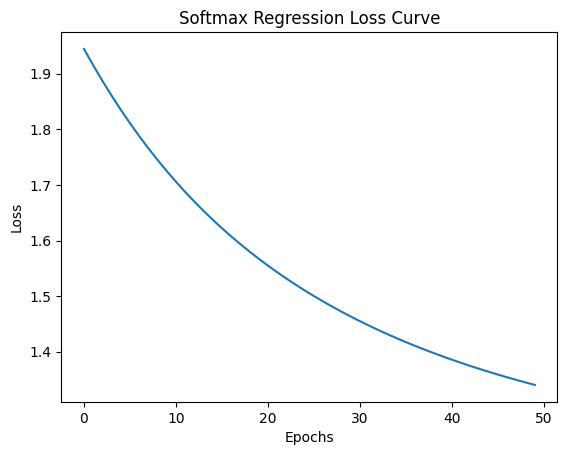

In [37]:
np.random.seed(42)

class SoftmaxRegression:
    def __init__(self, learning_rate=0.1, epochs=50, n_classes=3):
        self.lr = learning_rate
        self.epochs = epochs
        self.n_classes = n_classes
        self.weights = None
        self.loss_history = []
        self.classes = []

    def softmax(self, logits):
        # Subtract max for numerical stability (prevents exp overflow)
        exp_logits = np.exp(logits - np.max(logits, axis=1, keepdims=True))
        return exp_logits / np.sum(exp_logits, axis=1, keepdims=True)

    # This function returns the one-hot encodings of the labels in the data.
    def one_hot_encode(self, y):
        one_hot = np.zeros((len(y), self.n_classes))
        one_hot[np.arange(len(y)), y] = 1
        return one_hot

    def fit(self, X, y):
        self.classes = np.unique(y)
        n, f = X.shape

        # Weight Initialization with random small weights
        self.weights = np.random.rand(f, self.n_classes) * 0.01

        y_one_hot = self.one_hot_encode(y)

        for i in range(self.epochs):
            # TODO: Forward pass (linear model + softmax)
            logits = np.dot(X, self.weights)
            y_pred = self.softmax(logits)

            # TODO: Compute loss.
            y_pred = np.clip(y_pred, 1e-15, 1 - 1e-15)
            loss = -np.mean(np.sum(y_one_hot * np.log(y_pred), axis=1))
            self.loss_history.append(loss)

            # TODO: Backward pass (gradient descent)
            # Calculate the gradient and update the parameters
            gradient = np.dot(X.T, (y_pred - y_one_hot)) / n
            self.weights -= self.lr * gradient


    def predict(self, X):
        # TODO: Implement this function which will output the model prediction (the assigned classes) on X
        logits = np.dot(X, self.weights)

        probs = self.softmax(logits)

        best_class_indices = np.argmax(probs, axis=1)

        return self.classes[best_class_indices]

# Train Softmax and evaluate on the test split
# Get the actual number of unique classes from the training data
n_classes_data = len(np.unique(y_train))
softmax_model = SoftmaxRegression(learning_rate=0.1, epochs=50, n_classes=n_classes_data)
softmax_model.fit(X_train_aug, y_train)
y_pred_soft = softmax_model.predict(X_test_aug)

print("Softmax Accuracy:", accuracy_score(y_test, y_pred_soft))

# Plot Softmax Loss
plt.plot(softmax_model.loss_history)
plt.title('Softmax Regression Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

**Q7**: Consider a multiclass classification problem with $K$ classes, trained using Softmax logistic regression on a dataset containing $N$ samples, each with $f$ features. Answer the following questions in terms of $N$, $f$ and $K$:

a) How many classifiers are trained?

Exactly 1 classifier is trained. Unlike the OvR or OvO strategies that require training an ensemble of multiple independent binary models, Softmax regression is a true multiclass algorithm. It handles all K classes simultaneously inside a single, unified neural-network-like layer.

b) What is the total number of parameters?

The total number of parameters is K×f. The single Softmax model maintains a weight matrix of shape (f,K), where each of the K classes has its own dedicated weight vector of size f to calculate its respective class score (logit). Since no independent bias term is included in this assignment's code, the total parameter count scales directly as the product of the features and the classes.

c) How many training samples are used to train each classifier?

The single classifier uses all N samples available in the dataset. Because Softmax regression optimizes a global cross-entropy loss function over a probability distribution spanning all categories at once, every single data point is utilized in every forward and backward pass to update the entire weight matrix.

**Answer:**